In [2]:
# 04 - Executive HR Workforce Visualizations

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

sns.set_theme(style='whitegrid', palette='deep')

ROOT = Path(r"C:\Users\ravi3\Desktop\repo_backup\Hr-people-analytics")
VIS = ROOT / "visuals"
VIS.mkdir(exist_ok=True)

with open(ROOT / 'dashboards' / 'dashboard_data.json') as f:
    d = json.load(f)

results = {
    'Q2': {'sample': d['attrition_trend']},
    'Q3': {'sample': d['attrition_by_dept']},
    'Q8': {'sample': d['pay_gap_by_level']},
    'Q12': {'sample': d['high_perf_attrition']},
    'Q13': {'sample': d['exit_reasons']},
    'Q17': {'sample': d['cost_by_dept']},
}
print("Loaded all 6 analytical datasets successfully!")


Loaded all 6 analytical datasets successfully!


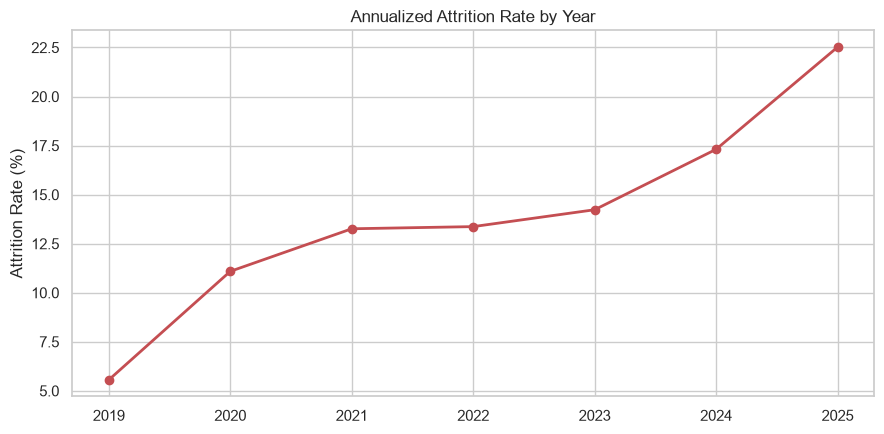

In [3]:
## Cell 2: Chart 1 - Annualized Attrition Rate Over Time (2019-2025)

att = pd.DataFrame(results['Q2']['sample'])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(att['yr'], att['attrition_rate_pct'], marker='o', linewidth=2, color=sns.color_palette('deep')[3])
ax.set_title('Annualized Attrition Rate by Year')
ax.set_ylabel('Attrition Rate (%)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(VIS / 'attrition_rate_trend.png', dpi=140)
plt.show()


C:\Users\ravi3\AppData\Local\Temp\ipykernel_20980\1015808249.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='attrition_rate_pct', y='department', data=dept, ax=ax, palette='flare')


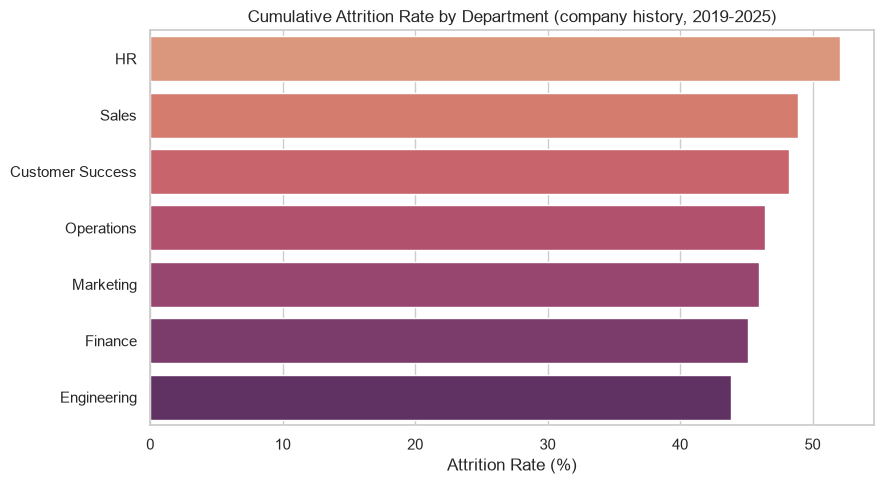

In [4]:
## Cell 3: Chart 2 - Cumulative Attrition Rate by Department

dept = pd.DataFrame(results['Q3']['sample']).sort_values('attrition_rate_pct', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x='attrition_rate_pct', y='department', data=dept, ax=ax, palette='flare')
ax.set_title('Cumulative Attrition Rate by Department (company history, 2019-2025)')
ax.set_xlabel('Attrition Rate (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(VIS / 'attrition_by_department.png', dpi=140)
plt.show()


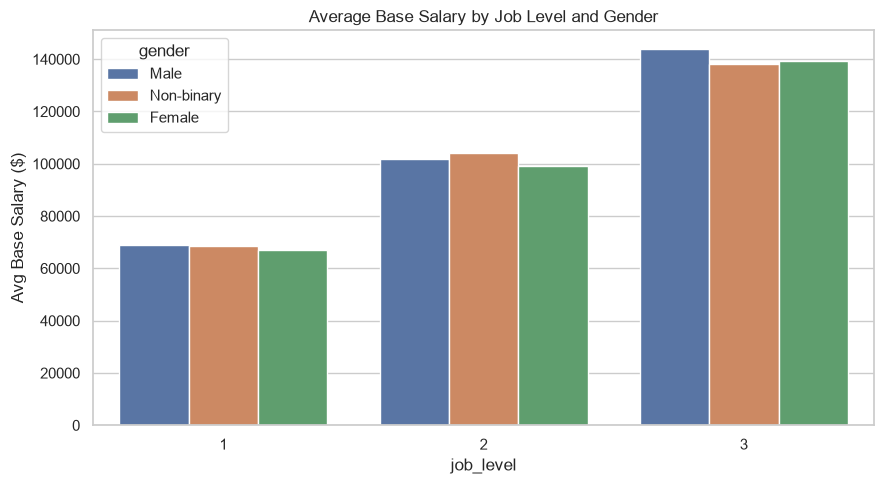

In [5]:
## Cell 4: Chart 3 - Average Base Salary by Job Level and Gender

gp = pd.DataFrame(results['Q8']['sample'])
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x='job_level', y='avg_base_salary', hue='gender', data=gp, ax=ax, palette='deep')
ax.set_title('Average Base Salary by Job Level and Gender')
ax.set_ylabel('Avg Base Salary ($)')
plt.tight_layout()
plt.savefig(VIS / 'pay_gap_by_level.png', dpi=140)
plt.show()


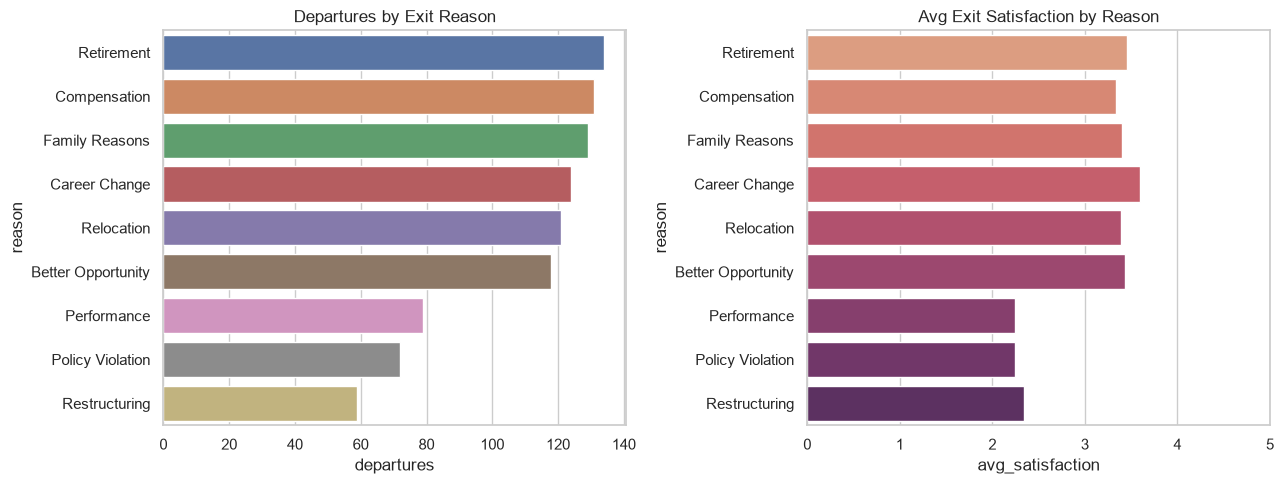

In [6]:
## Cell 5: Chart 4 - Exit Reasons and Post-Exit Satisfaction (Side-by-Side Subplots)

ex = pd.DataFrame(results['Q13']['sample']).sort_values('departures', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x='departures', y='reason', hue='reason', legend=False, data=ex, ax=axes[0], palette='deep')
axes[0].set_title('Departures by Exit Reason')

sns.barplot(x='avg_satisfaction', y='reason', hue='reason', legend=False, data=ex, ax=axes[1], palette='flare')
axes[1].set_title('Avg Exit Satisfaction by Reason')
axes[1].set_xlim(0, 5)

plt.tight_layout()
plt.savefig(VIS / 'exit_reasons.png', dpi=140)
plt.show()


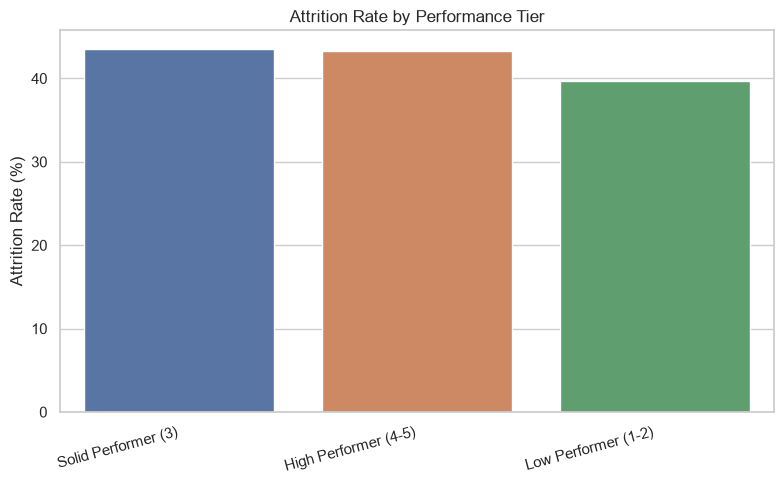

In [7]:
## Cell 6: Chart 5 - Attrition Rate by Performance Tier

perf = pd.DataFrame(results['Q12']['sample'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x='performance_tier', y='attrition_rate_pct', hue='performance_tier', legend=False, data=perf, ax=ax, palette='deep')
ax.set_title('Attrition Rate by Performance Tier')
ax.set_ylabel('Attrition Rate (%)')
ax.set_xlabel('')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(VIS / 'attrition_by_performance.png', dpi=140)
plt.show()


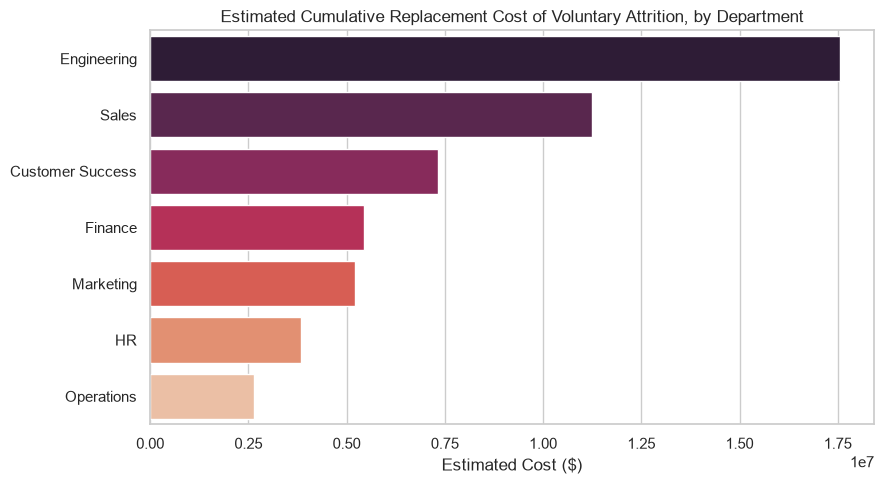

In [8]:
## Cell 7: Chart 6 - Estimated Cumulative Replacement Cost of Voluntary Attrition by Department

cost = pd.DataFrame(results['Q17']['sample']).sort_values('estimated_replacement_cost', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x='estimated_replacement_cost', y='department', hue='department', legend=False, data=cost, ax=ax, palette='rocket')
ax.set_title('Estimated Cumulative Replacement Cost of Voluntary Attrition, by Department')
ax.set_xlabel('Estimated Cost ($)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(VIS / 'attrition_cost_by_department.png', dpi=140)
plt.show()
